# Disease Prediction from Symptoms using Machine Learning
> **Goal:** Build an end-to-end Machine Learning pipeline to predict disease diagnoses based on user symptoms, evaluate model performance, visualize key medical analytics graphs, and provide an interactive prediction interface.

### Features Covered:
- Data ingestion & cleaning (handling extra columns and missing values)
- Exploratory Data Analysis (EDA) with disease distribution & symptom frequency graphs
- Stratified Train-Test Splitting
- Random Forest Classifier training & hyperparameter configuration
- Multi-Model Comparison (Random Forest, Logistic Regression, Decision Tree, Naive Bayes, SVM)
- Evaluation Metrics: Accuracy, Precision, Recall, F1-Score & Annotated Confusion Matrix
- Feature Importance Analysis (Top predictive symptoms)
- Interactive Prediction Function with Confidence Breakdown Bar Chart
- Model serialization (`disease_model.pkl`) for web application integration

## 1. Load and Clean Dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load dataset (supporting both local environment and Google Colab)
train_path = 'Training.csv' if os.path.exists('Training.csv') else '/content/Training.csv'
test_path = 'Testing.csv' if os.path.exists('Testing.csv') else '/content/Testing.csv'

df = pd.read_csv(train_path)

# Drop artifact column if present (e.g. Unnamed: 133 created by trailing commas)
if 'Unnamed: 133' in df.columns:
    df = df.drop(columns=['Unnamed: 133'])

print(f"Dataset successfully loaded: {df.shape[0]} rows and {df.shape[1]} columns")
df.head()

Dataset successfully loaded: 4920 rows and 133 columns


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


## 2. Exploratory Data Analysis & Distribution Graphs

Total Symptoms: 132 | Total Target Diseases: 41


C:\Users\Akhilesh\AppData\Local\Temp\ipykernel_323004\787593773.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=disease_counts.index, y=disease_counts.values, palette='viridis')


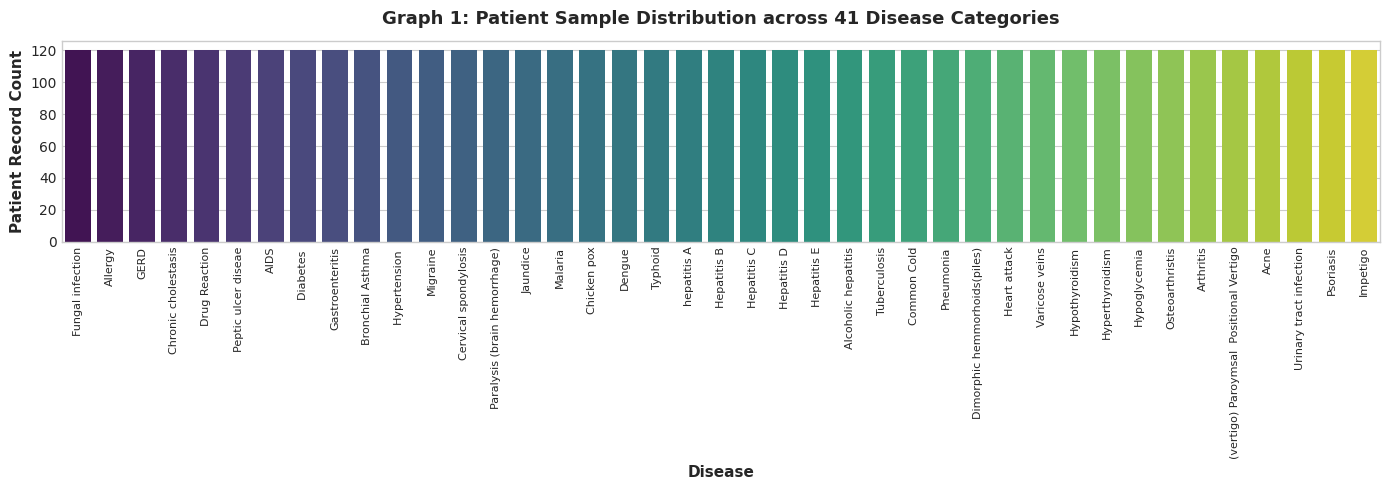

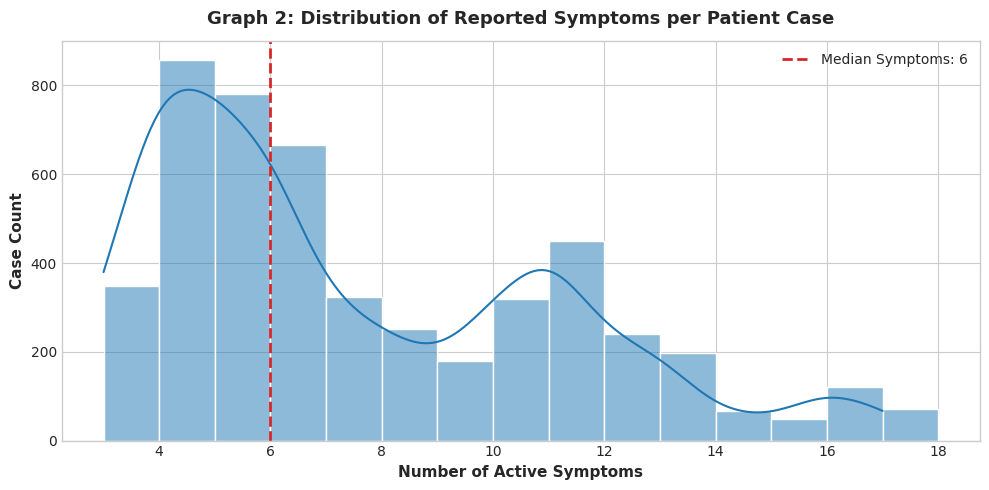

In [2]:
# Overview statistics
symptoms_list = [col for col in df.columns if col != 'prognosis']
num_symptoms = len(symptoms_list)
num_diseases = df['prognosis'].nunique()

print(f"Total Symptoms: {num_symptoms} | Total Target Diseases: {num_diseases}")

# GRAPH 1: Disease Class Distribution
plt.figure(figsize=(14, 5))
disease_counts = df['prognosis'].value_counts()
sns.barplot(x=disease_counts.index, y=disease_counts.values, palette='viridis')
plt.title('Graph 1: Patient Sample Distribution across 41 Disease Categories', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Disease', fontsize=11, fontweight='bold')
plt.ylabel('Patient Record Count', fontsize=11, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

# GRAPH 2: Active Symptoms Distribution per Patient
symptom_counts = df[symptoms_list].sum(axis=1)
plt.figure(figsize=(10, 5))
sns.histplot(symptom_counts, bins=range(int(symptom_counts.min()), int(symptom_counts.max()) + 2), 
             kde=True, color='#1f77b4', edgecolor='white')
plt.axvline(symptom_counts.median(), color='#d62728', linestyle='--', linewidth=2, 
            label=f'Median Symptoms: {symptom_counts.median():.0f}')
plt.title('Graph 2: Distribution of Reported Symptoms per Patient Case', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Number of Active Symptoms', fontsize=11, fontweight='bold')
plt.ylabel('Case Count', fontsize=11, fontweight='bold')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 3. Train-Test Split (Stratified)

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop('prognosis', axis=1)
y = df['prognosis']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples | Validation set: {X_val.shape[0]} samples")

# Also load official Testing.csv benchmark if available
if os.path.exists(test_path):
    df_test = pd.read_csv(test_path)
    if 'Unnamed: 133' in df_test.columns:
        df_test = df_test.drop(columns=['Unnamed: 133'])
    X_benchmark = df_test.drop('prognosis', axis=1)
    y_benchmark = df_test['prognosis']
    print(f"External Benchmark Testing set: {X_benchmark.shape[0]} samples")
else:
    X_benchmark, y_benchmark = X_val, y_val

Training set: 3936 samples | Validation set: 984 samples
External Benchmark Testing set: 42 samples


## 4. Train Primary Model: Random Forest Classifier

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# Evaluation
y_val_pred = rf_model.predict(X_val)
val_acc = accuracy_score(y_val, y_val_pred)
print(f"Random Forest Validation Accuracy: {val_acc * 100:.2f}%")

y_bench_pred = rf_model.predict(X_benchmark)
bench_acc = accuracy_score(y_benchmark, y_bench_pred)
print(f"Random Forest Testing.csv Benchmark Accuracy: {bench_acc * 100:.2f}%\n")
print(classification_report(y_benchmark, y_bench_pred, zero_division=0))

Random Forest Validation Accuracy: 100.00%
Random Forest Testing.csv Benchmark Accuracy: 97.62%

                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       0.50      1.00      0.67         1
                    Chronic cholestasis       1.00      1.00      1.00         1
           

## 5. Graph 3: Confusion Matrix Heatmap

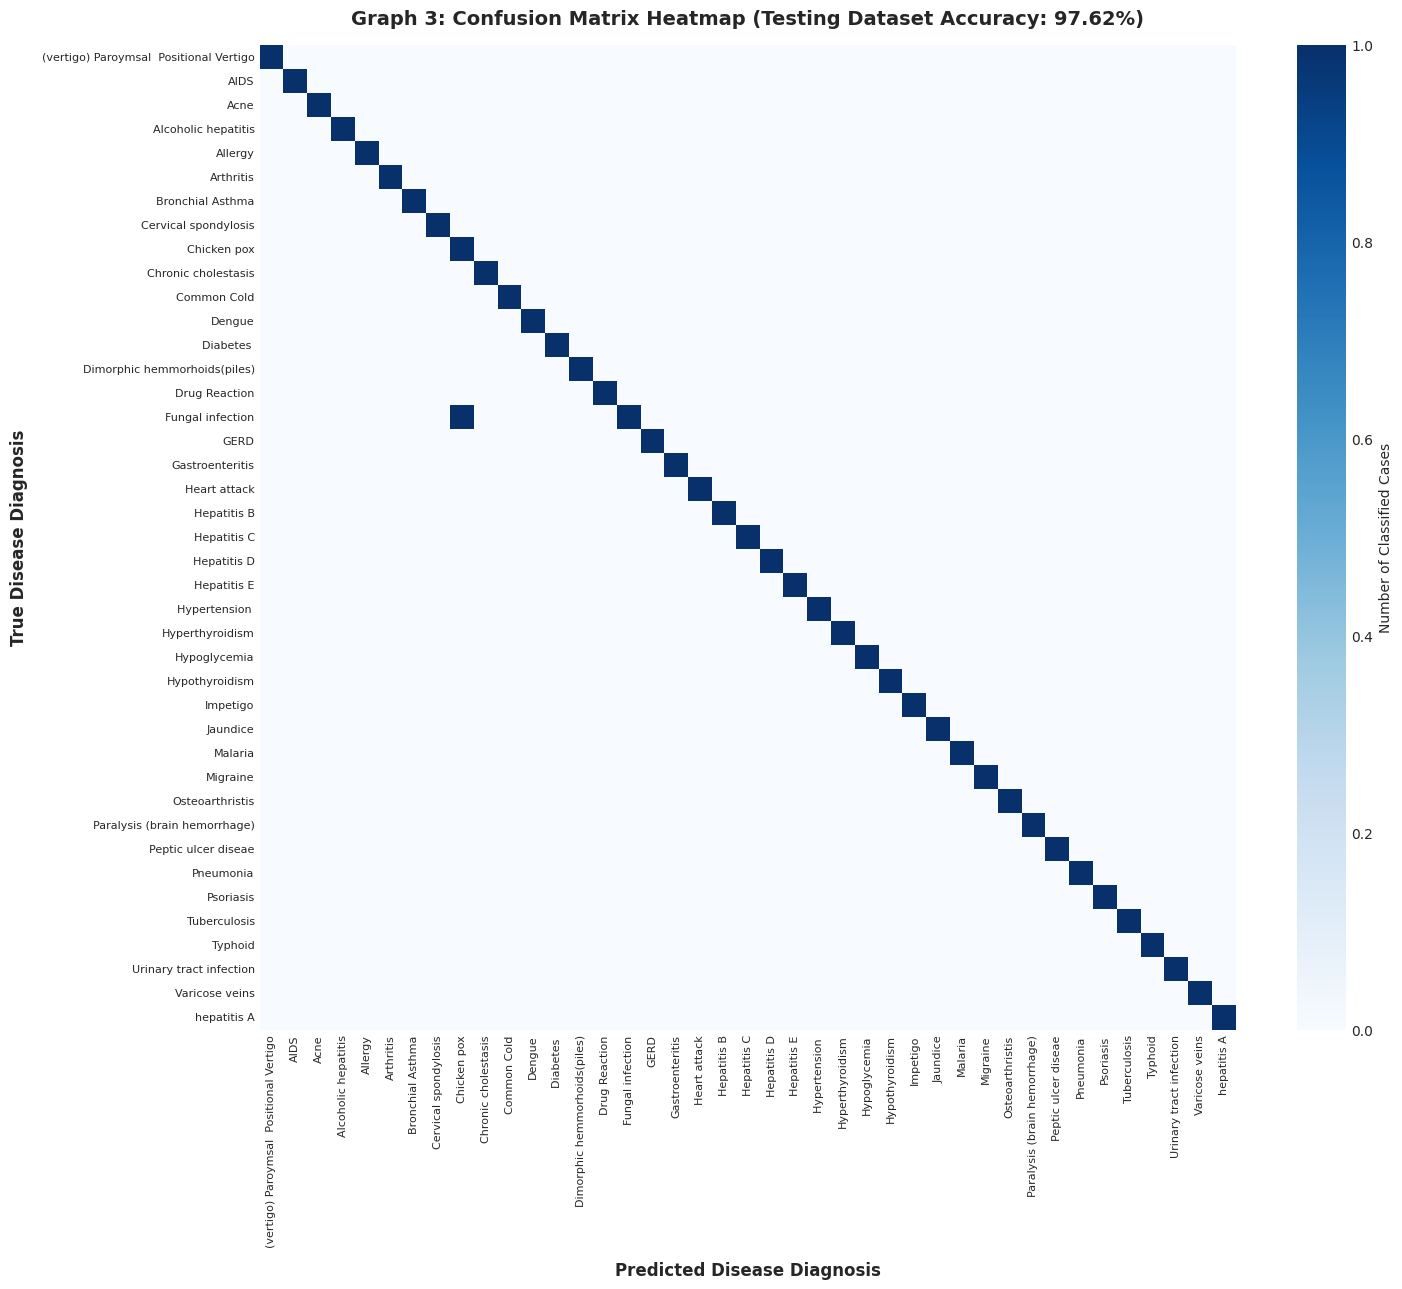

In [5]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_benchmark, y_bench_pred, labels=rf_model.classes_)

plt.figure(figsize=(15, 13))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=rf_model.classes_, yticklabels=rf_model.classes_,
            cbar_kws={'label': 'Number of Classified Cases'})
plt.xlabel('Predicted Disease Diagnosis', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('True Disease Diagnosis', fontsize=12, fontweight='bold', labelpad=10)
plt.title(f'Graph 3: Confusion Matrix Heatmap (Testing Dataset Accuracy: {bench_acc*100:.2f}%)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Graph 4: Feature Importance (Top 20 Predictive Symptoms)

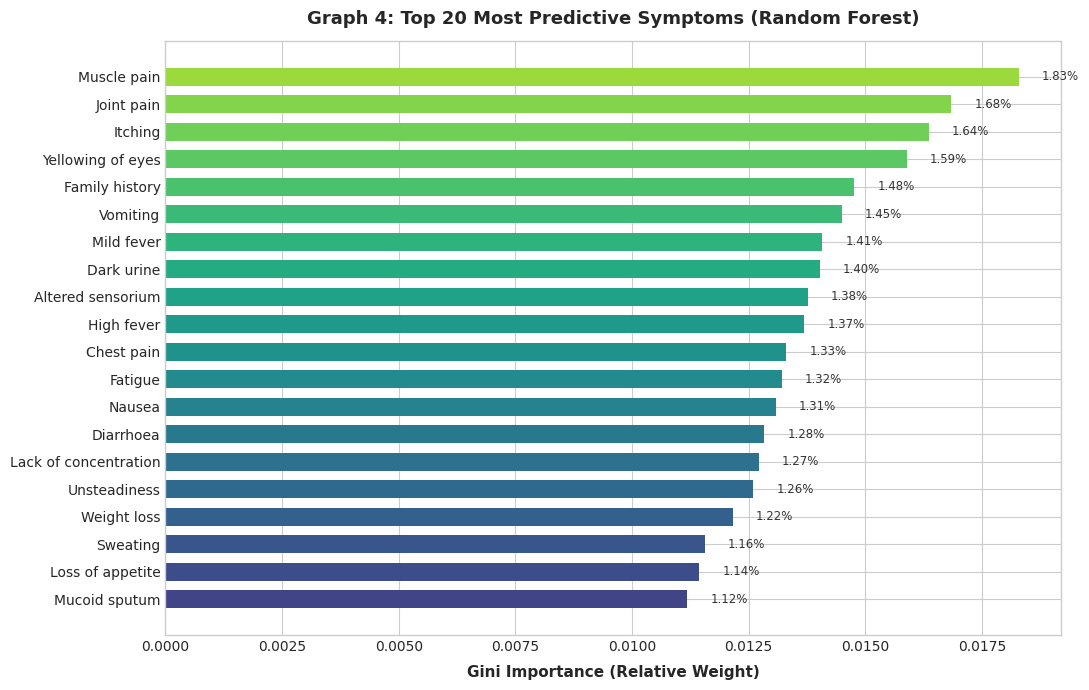

In [6]:
importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[::-1][:20]
top_symptoms = [X.columns[i].replace('_', ' ').capitalize() for i in top_indices]
top_scores = importances[top_indices]

plt.figure(figsize=(11, 7))
colors = plt.cm.viridis(np.linspace(0.2, 0.85, 20))
bars = plt.barh(range(20), top_scores[::-1], color=colors, height=0.65)
plt.yticks(range(20), top_symptoms[::-1], fontsize=10, fontweight='medium')
plt.xlabel('Gini Importance (Relative Weight)', fontsize=11, fontweight='bold', labelpad=8)
plt.title('Graph 4: Top 20 Most Predictive Symptoms (Random Forest)', fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.0005, bar.get_y() + bar.get_height()/2, f'{w*100:.2f}%', 
             va='center', ha='left', fontsize=8.5, color='#333333')

plt.tight_layout()
plt.show()

## 7. Graph 5: Multi-Model Algorithm Comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.97619,0.988095,0.97619,0.97619
1,Logistic Regression,1.00000,1.000000,1.00000,1.00000
2,Decision Tree,0.97619,0.988095,0.97619,0.97619
3,Gaussian Naive Bayes,1.00000,1.000000,1.00000,1.00000
4,Support Vector Machine,1.00000,1.000000,1.00000,1.00000


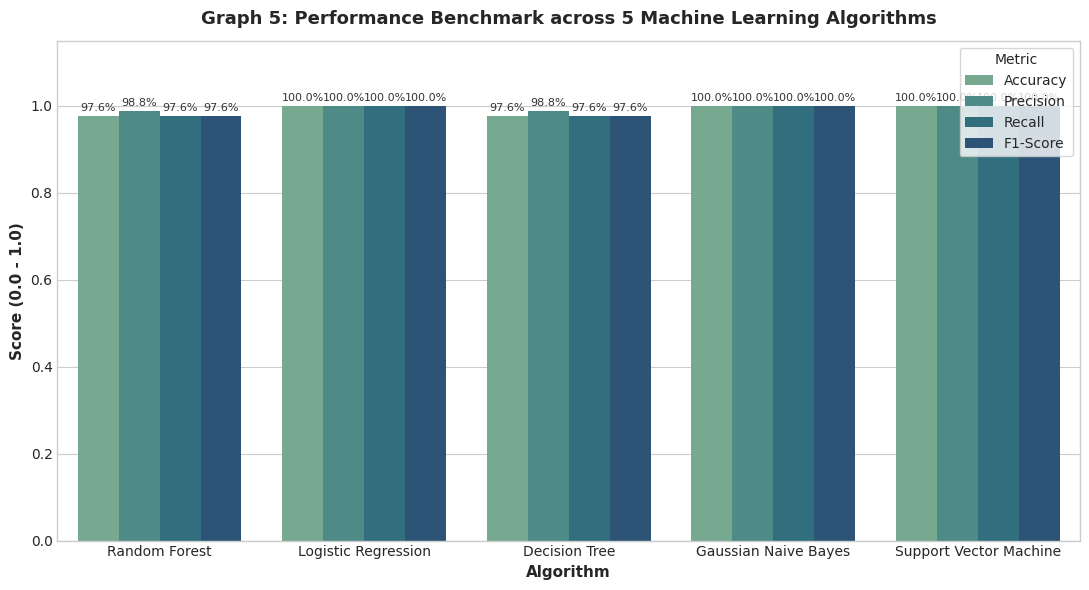

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score

candidate_models = {
    'Random Forest': rf_model,
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(random_state=42)
}

comparison_data = []

for name, clf in candidate_models.items():
    if name != 'Random Forest':
        clf.fit(X_train, y_train)
    preds = clf.predict(X_benchmark)
    acc = accuracy_score(y_benchmark, preds)
    prec = precision_score(y_benchmark, preds, average='weighted', zero_division=0)
    rec = recall_score(y_benchmark, preds, average='weighted', zero_division=0)
    f1 = f1_score(y_benchmark, preds, average='weighted', zero_division=0)
    
    comparison_data.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

comp_df = pd.DataFrame(comparison_data)
display(comp_df)

# GRAPH 5: Multi-Model Metric Bar Chart
plt.figure(figsize=(11, 6))
comp_melted = comp_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
ax = sns.barplot(data=comp_melted, x='Model', y='Score', hue='Metric', palette='crest')
plt.title('Graph 5: Performance Benchmark across 5 Machine Learning Algorithms', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Score (0.0 - 1.0)', fontsize=11, fontweight='bold')
plt.xlabel('Algorithm', fontsize=11, fontweight='bold')
plt.ylim(0, 1.15)
plt.legend(title='Metric', frameon=True, loc='upper right')

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h*100:.1f}%', (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8, color='#333333', xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## 8. Save Trained Model to Disk

In [8]:
import joblib

model_filename = "disease_model.pkl"
joblib.dump(rf_model, model_filename)
print(f"Model serialized and saved successfully as '{model_filename}'")

Model serialized and saved successfully as 'disease_model.pkl'


## 9. Interactive Disease Prediction Function with Confidence Graph

INPUT SYMPTOMS: fever, headache, chills, fatigue, muscle_pain
PRIMARY PREDICTION: Malaria (46.5% confidence)
TOP PROBABILITIES:
  • Malaria                       :  46.50%
  • Allergy                       :  13.50%
  • Dengue                        :   6.50%
  • Typhoid                       :   5.50%
  • Paralysis (brain hemorrhage)  :   5.00%


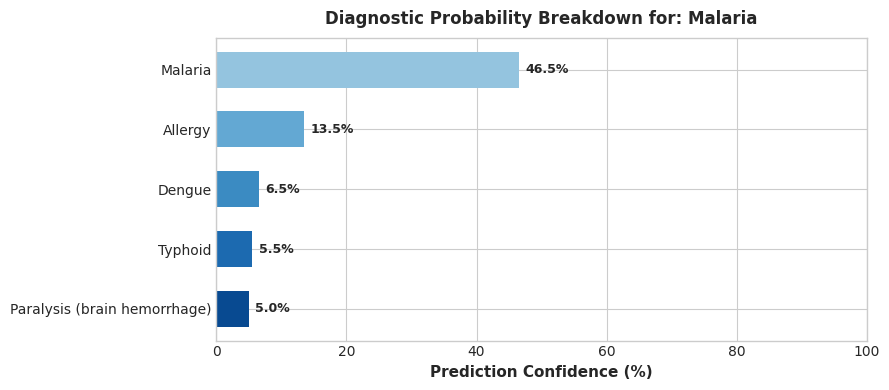

In [9]:
def predict_disease(symptoms, top_k=5, plot_confidence=True):
    """
    Predict the most likely disease diagnosis based on a list of input symptoms.
    
    Parameters:
        symptoms (list of str): List of symptom strings (e.g., ['fever', 'headache', 'chills'])
        top_k (int): Number of top disease candidates to display with probabilities
        plot_confidence (bool): If True, renders a horizontal bar chart of probabilities
        
    Returns:
        dict: Top predicted disease name and confidence probabilities
    """
    # Create binary vector aligned with X.columns
    input_vector = {col: (1 if col in symptoms else 0) for col in X.columns}
    input_df = pd.DataFrame([input_vector])
    
    # Predict probabilities across classes
    probabilities = rf_model.predict_proba(input_df)[0]
    classes = rf_model.classes_
    
    # Sort by descending probability
    sorted_indices = np.argsort(probabilities)[::-1]
    top_diseases = [classes[i] for i in sorted_indices[:top_k]]
    top_probs = [probabilities[i] for i in sorted_indices[:top_k]]
    
    predicted_disease = top_diseases[0]
    top_confidence = top_probs[0]
    
    print("=" * 55)
    print(f"INPUT SYMPTOMS: {', '.join(symptoms)}")
    print(f"PRIMARY PREDICTION: {predicted_disease} ({top_confidence * 100:.1f}% confidence)")
    print("=" * 55)
    print("TOP PROBABILITIES:")
    for d, p in zip(top_diseases, top_probs):
        print(f"  • {d:30s}: {p * 100:6.2f}%")
        
    if plot_confidence and top_confidence > 0:
        plt.figure(figsize=(9, 4))
        colors = plt.cm.Blues(np.linspace(0.4, 0.9, top_k))[::-1]
        bars = plt.barh(range(top_k), [p * 100 for p in top_probs[::-1]], color=colors, height=0.6)
        plt.yticks(range(top_k), top_diseases[::-1], fontsize=10)
        plt.xlabel('Prediction Confidence (%)', fontsize=11, fontweight='bold')
        plt.title(f'Diagnostic Probability Breakdown for: {predicted_disease}', fontsize=12, fontweight='bold', pad=10)
        plt.xlim(0, max(100, max(top_probs)*100 + 15))
        
        for bar in bars:
            w = bar.get_width()
            plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')
            
        plt.tight_layout()
        plt.show()
        
    return {
        "primary_prediction": predicted_disease,
        "confidence": top_confidence,
        "top_candidates": list(zip(top_diseases, top_probs))
    }

# Test Prediction 1: Flu / Fever scenario
result1 = predict_disease(['fever', 'headache', 'chills', 'fatigue', 'muscle_pain'])

### Test Sample 2: Skin Rash / Infection

INPUT SYMPTOMS: itching, skin_rash, nodal_skin_eruptions, dischromic _patches
PRIMARY PREDICTION: Fungal infection (100.0% confidence)
TOP PROBABILITIES:
  • Fungal infection              : 100.00%
  • Varicose veins                :   0.00%
  • Urinary tract infection       :   0.00%
  • Typhoid                       :   0.00%
  • Tuberculosis                  :   0.00%


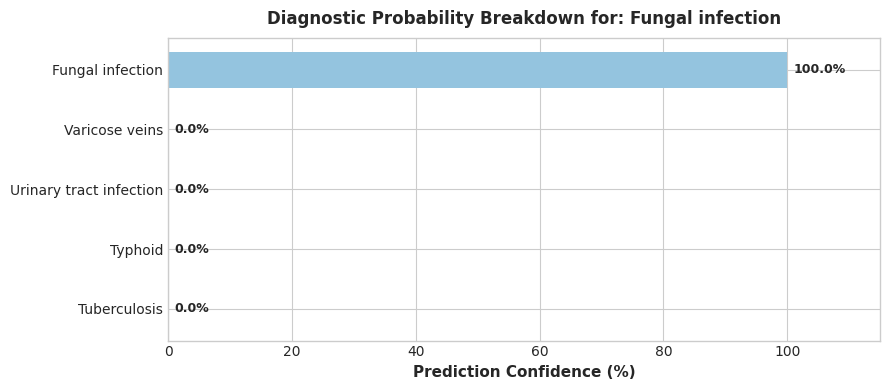

In [10]:
# Test Prediction 2: Skin condition
result2 = predict_disease(['itching', 'skin_rash', 'nodal_skin_eruptions', 'dischromic _patches'])